# 02 - Modelos baseline

**Objetivo:** establecer el rendimiento de referencia para predecir el Carbono Orgánico del Suelo (`ORGC`, %) en base al analsis de los papers analizados .

**Baselines:**
1. **Media** y **Mediana**: predicen siempre un valor constante (piso de rendimiento, R² ≈ 0).
2. **Regresión Lineal Múltiple**: referencia lineal con imputación (mediana) y escalamiento.
3. **Regresión Lineal Múltiple sobre `log1p(ORGC)`**: `ORGC` es muy asimétrica; se evalúa si transformar el target ayuda.

**Decisiones metodológicas:**
- Las capas de un mismo perfil (`profile_code`) son muy parecidas entre sí. La división se hace **agrupada por perfil** para que ninguna capa de un perfil de prueba aparezca en entrenamiento.
- Imputación y escalamiento se ajustan solo con los datos de entrenamiento (dentro del `Pipeline`).
- Las métricas se reportan siempre en la escala original de `ORGC`.

In [2]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from preprocessing import load_data, prepare_data
from models import get_baseline_models
from evaluation import (filter_valid_target, group_train_test_split,
                        evaluate_models, cross_validate_grouped)

pd.set_option('display.float_format', '{:.4f}'.format)

## 1. Carga de datos

In [10]:
df = load_data('../data/raw/allpaDB_layer_HARMONIZED_v1.csv')
X, y = prepare_data(df)               # elimina filas sin ORGC
groups = df.loc[X.index, 'profile_code']

print(f'Filas totales: {len(df)}')
print(f'Filas con ORGC: {len(y)}')
print(f'Filas sin identificador de perfil: {groups.isnull().sum()}')

Filas totales: 24341
Filas con ORGC: 21609
Filas sin identificador de perfil: 0


In [4]:
X, y, groups = filter_valid_target(X, y, groups)   # elimina ORGC > 100 %
print(f'Filas tras eliminar ORGC > 100 %: {len(y)}')
print(f'Perfiles distintos: {groups.nunique()}')
y.describe()

Filas tras eliminar ORGC > 100 %: 21601
Perfiles distintos: 8206


count   21601.0000
mean        1.9966
std         5.3468
min         0.0000
25%         0.2800
50%         0.6900
75%         1.5255
max        98.7800
Name: ORGC, dtype: float64

## 2. División entrenamiento / prueba (agrupada por perfil)

In [5]:
X_train, X_test, y_train, y_test, g_train, g_test = group_train_test_split(X, y, groups, test_size=0.2, random_state=42)

print(f'Entrenamiento: {len(X_train)} filas, {g_train.nunique()} perfiles')
print(f'Prueba:        {len(X_test)} filas, {g_test.nunique()} perfiles')
print(f'Perfiles en ambos conjuntos: {len(set(g_train) & set(g_test))}')

Entrenamiento: 17349 filas, 6564 perfiles
Prueba:        4252 filas, 1642 perfiles
Perfiles en ambos conjuntos: 0


## 3. Entrenamiento y evaluación

In [6]:
models = get_baseline_models()
results = evaluate_models(models, X_train, y_train, X_test, y_test)
results.pivot(index='Modelo', columns='Conjunto', values=['R2', 'RMSE', 'MAE']).loc[list(models)]

R2           RMSE           MAE       
Conjunto                       test   train   test  train   test  train
Modelo                                                                 
Media                       -0.0002  0.0000 5.1030 5.4048 2.1635 2.2269
Mediana                     -0.0608 -0.0606 5.2554 5.5662 1.6369 1.7105
Regresion Lineal             0.0925  0.0875 4.8608 5.1628 2.1215 2.1533
Regresion Lineal (log ORGC)  0.0530  0.0425 4.9655 5.2886 1.5445 1.6049

## 4. Validación cruzada agrupada por perfil (5 folds)

La división única puede ser optimista o pesimista según qué perfiles caigan en prueba. La validación cruzada muestra la variabilidad de las métricas.

In [7]:
cv_folds, cv_summary = cross_validate_grouped(models, X, y, groups, n_splits=5)
cv_summary

R2          RMSE           MAE       
                               mean    std   mean    std   mean    std
Modelo                                                                
Media                       -0.0002 0.0002 5.3401 0.3006 2.2058 0.0543
Mediana                     -0.0601 0.0056 5.4975 0.3047 1.6962 0.0685
Regresion Lineal             0.0877 0.0077 5.1005 0.2980 2.1412 0.0337
Regresion Lineal (log ORGC)  0.0435 0.0075 5.2229 0.3131 1.5918 0.0618

## 5. Análisis de predicciones

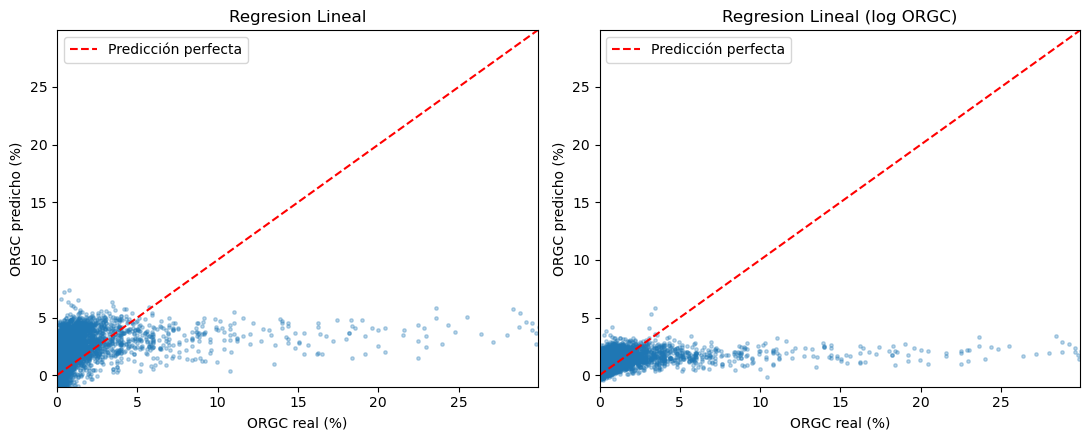

In [8]:
fitted = {name: model.fit(X_train, y_train) for name, model in models.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
lim = y_test.quantile(0.99)
for ax, name in zip(axes, ['Regresion Lineal', 'Regresion Lineal (log ORGC)']):
    pred = fitted[name].predict(X_test)
    ax.scatter(y_test, pred, s=6, alpha=0.3)
    ax.plot([0, lim], [0, lim], 'r--', label='Predicción perfecta')
    ax.set_xlim(0, lim); ax.set_ylim(-1, lim)
    ax.set_xlabel('ORGC real (%)'); ax.set_ylabel('ORGC predicho (%)')
    ax.set_title(name); ax.legend()
plt.tight_layout(); plt.show()

In [9]:
pred_lin = fitted['Regresion Lineal'].predict(X_test)
print(f'Predicciones negativas de la regresión lineal: {(pred_lin < 0).sum()} de {len(pred_lin)} ({(pred_lin < 0).mean():.1%})')
print(f'Media de entrenamiento:   {y_train.mean():.4f}')
print(f'Mediana de entrenamiento: {y_train.median():.4f}')

Predicciones negativas de la regresión lineal: 443 de 4252 (10.4%)
Media de entrenamiento:   2.0109
Mediana de entrenamiento: 0.6800


Analisis de resultados:

- Nube casi horizontal en la gráfica. Un modelo perfecto pondría los puntos sobre la línea roja, pero aquí las predicciones quedan en un rango estrecho (≈ 0–5% en la regresión lineal y ≈ 0–3% en la versión log), sin importar el valor real.
- Subestima los valores altos. Para ORGC reales de 10–30% predice cerca de 2–5%. Esto concuerda con el R² bajo (≈ 0.09) y con la asimetría de la variable.
- Valores bajos. La mayoría de los datos tiene ORGC < 3%. Ahí las predicciones son más cercanas, pero con mucha dispersión.
- Versión log. Comprime aún más las predicciones, con menos valores negativos y menor MAE, pero subestima más los valores altos.
- Puntos bajo cero. Corresponden a las predicciones negativas de la regresión lineal, que no son válidas.


## 6. Conclusiones

En base a ese analsis se puede concluir que:

- Media y mediana. La media (R² ≈ 0, RMSE 5.10, MAE 2.16) es el piso de referencia. La mediana tiene un MAE menor (1.64) y un RMSE peor, porque ORGC es muy asimétrica.
- Regresión lineal. Mejora poco a la media (R² = 0.09, RMSE 4.86). Las variables disponibles explican linealmente cerca del 9% de la varianza, y la validación cruzada da lo mismo (R² = 0.089).
- Transformación logarítmica. Con log1p baja el MAE (1.54), pero empeora R² (0.05) y RMSE (4.97). Ajusta mejor los valores bajos y peor los altos.
- Predicciones negativas. El 10.4% de las predicciones de la regresión lineal son negativas, y eso no es válido para un porcentaje de carbono.
Siguiente paso. Estos valores son la referencia que Random Forest, XGBoost y MLP deben superar.